<a href="https://colab.research.google.com/github/acac2495/3D-BCH-Codes/blob/main/3D_BCH_code_p1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#Libraries

import numpy as np
import argparse
import itertools
import random

from tqdm.notebook import tqdm

In [ ]:
#Basic building block functions

ALPHA_POWERS = [8, 4, 2, 1, 12, 6, 3, 13, 10, 5, 14, 7, 15, 11, 9]  # a^0..a^14, MSB-first

EXP_STR = {0: "0"}
for idx, val in enumerate(ALPHA_POWERS):
    EXP_STR[val] = f"a^{idx}"

def alpha_pow(exp, n=15):
    return ALPHA_POWERS[exp % n]

def to_hex(val):
    return format(val, 'X')

#XOR array
def xor_array(c1, c2):
    c = [[0] * len(c1) for _ in range(len(c1))]
    for i in range(0, len(c1)):
        for j in range(0, len(c1[0])):
            c[i][j] = c1[i][j] ^ c2[i][j]
    return c

In [ ]:
#Used Constants

N = 15
t = 2
m = 4

In [ ]:
#Galois field operations

def gf_mul(a, b):
    if(a == 0 or b == 0):
        return 0
    p1 = ALPHA_POWERS.index(a)
    p2 = ALPHA_POWERS.index(b)
    return ALPHA_POWERS[(p1 + p2) % N]

def gf_pow(a, pow):
    if(a == 0):
        return 8
    p1 = ALPHA_POWERS.index(a)
    return ALPHA_POWERS[(p1 * pow) % N]

def gf_inv(a):
    if(a == 0):
        return 0
    p1 = ALPHA_POWERS.index(a)
    return ALPHA_POWERS[(N - p1) % N]

def alpha_pow(exp):
    return ALPHA_POWERS[exp % N]

In [ ]:
#Discrete Finite Field Fourier Transform

def dffft_pt(c, j, jp):
    acc = 0
    for i in range(N):
        for ip in range(N):
            if(c[i][ip]):
                acc ^= alpha_pow(i * j + ip * jp)
    return acc

def dffft_2t(c):
    C = [[0] * (2*t) for _ in range(2*t)]
    for j in range(1, 2*t + 1):
        for jp in range(1, 2*t + 1):
            C[j-1][jp-1] = dffft_pt(c, j, jp)
    return C

def dffft_full(c):
    C = [[0] * N for _ in range(N)]
    for j in range(1, N + 1):
        for jp in range(1, N + 1):
            C[j-1][jp-1] = dffft_pt(c, j, jp)
    return C

In [ ]:
#Inverse Discrete Finite Field Fourier Transform

def idffft_pt(C, i, ip):
    acc = 0
    for j in range(N):
        for jp in range(N):
            p1 = gf_inv(alpha_pow(i * j + ip * jp))
            acc ^= gf_mul(p1, C[j][jp])
    if(acc != 0):
        return 1
    else:
        return 0

def idffft_full(C):
    c = [[0] * N for _ in range(N)]
    for i in range(N):
        for ip in range(N):
            c[i][ip] = idffft_pt(C, i, ip)
    return c

In [ ]:
#Printing aids

def print_grid(C):
    for row in C:
        for elem in row:
            print(EXP_STR[elem], " | " , end=" ")
        print("")

def print_bin(err):
    for row in err:
        print(row)

In [ ]:
#Fixed Berlekamp Massey Engine

def BM_fixed(synds):
    sigma   = [0] * (t + 1);  sigma[0] = 8
    sigma_p = [0] * (t + 1);  sigma_p[1] = 8
    d_p = 8
    L = 0
    temp_reg = [0] * (t + 1)
    for i in range(2 * t):
        temp_reg = [synds[i]] + temp_reg[0:t]
        d_mu = temp_reg[0]
        for j in range(1, t + 1):
            d_mu ^= gf_mul(temp_reg[j], sigma[j])

        dmu_dpinv = gf_mul(d_mu, gf_inv(d_p))
        corr = [gf_mul(sigma_p[j], dmu_dpinv) for j in range(t + 1)]
        sigma_next = [sigma[j] ^ corr[j] for j in range(t + 1)]

        load_sigma = 1 if (d_mu != 0 and 2 * L <= i) else 0
        sigma_store = sigma[:] if load_sigma else sigma_p[:]
        sigma_p = [0] + sigma_store[0:t]
        sigma = sigma_next
        if load_sigma:
            d_p = d_mu
            L = i + 1 - L
    return sigma

In [ ]:
#Polynomial and Root functions

def print_poly(sigma):
    powers = []
    for coeff in sigma:
        powers.append(EXP_STR[coeff])
    print(powers)

def print_roots(sigma):
    for i in ALPHA_POWERS:
        res = 8
        for j in range(1, t+1):
            pow = gf_pow(i, j)
            res ^= gf_mul(pow, sigma[j])
        if(res == 0):
            print(EXP_STR[i], end=" ")

def display_roots(roots):
    for root in roots:
        print(EXP_STR[root], end=" ")
    print("")

def get_rpos(sigma):
    rpos = []
    for i in ALPHA_POWERS:
        res = 8
        for j in range(1, t+1):
            pow = gf_pow(i, j)
            res ^= gf_mul(pow, sigma[j])
        if(res == 0):
            rpos.append(1)
        else:
            rpos.append(0)
    return rpos

def root_lookup(rpos):
    count = 0
    roots = []
    for i in range(len(rpos)):
        if(rpos[i] == 1):
            roots.append(ALPHA_POWERS[i])
            count += 1
        if(count == t):
            break
    return roots

def root_to_coeff(roots):
    if len(roots) >= 2:
        a1, a2 = roots[0], roots[1]
        prod = gf_mul(a1, a2)
        return [8, gf_mul(a1 ^ a2, gf_inv(prod)), gf_inv(prod)]
    if len(roots) == 1:
        return [8, gf_inv(roots[0]), 0]
    return [8, 0, 0]

In [ ]:
#Recursive Extension basic functions

def RE_base(c, window):
    res = 0
    for i in range(1, t + 1):
        res ^= gf_mul(c[i], window[-i])
    return res

def RE_chain(c, S_init):
    window = list(S_init)
    out = []
    for _ in range(N - 2 * t):
        new = RE_base(c, window)
        out.append(new)
        window = window[1:] + [new]
    return out


In [ ]:
#Recursive extension row and column wise

def extend_columns(S_2t, col_ccp_poly):
    S_full = [[0] * (2 * t) for _ in range(N)]
    for k in range(2*t):
        seq = [S_2t[j][k] for j in range(2*t)]
        seq_full = seq + RE_chain(col_ccp_poly, seq[-t:])
        for j in range(N):
            S_full[j][k] = seq_full[j]
    return S_full

def extend_rows(col_full, row_ccp_poly):
    S_full = []
    for j in range(N):
        seq = list(col_full[j])
        S_full.append(seq + RE_chain(row_ccp_poly, seq[-t:]))
    return S_full

In [ ]:
#Full datapath implementation

def ecc_2d_silent(r_in):
    S_2t = dffft_2t(r_in)
    S_2t_arrnp = np.array(S_2t)
    S_2t_colwise = np.transpose(S_2t_arrnp).tolist()

    col_poly = []
    row_poly = []

    for j in S_2t:
        row_poly.append(BM_fixed(j))
    for j in S_2t_colwise:
        col_poly.append(BM_fixed(j))

    col_rpos = []
    row_rpos = []

    for sigma in col_poly:
        col_rpos.append(get_rpos(sigma))
    for sigma in row_poly:
        row_rpos.append(get_rpos(sigma))

    col_rpos_lcm = 0
    row_rpos_lcm = 0

    col_rpos_lcm = [0] * N
    row_rpos_lcm = [0] * N

    for rpos in col_rpos:
        col_rpos_lcm = [a | b for a, b in zip(col_rpos_lcm, rpos)]
    for rpos in row_rpos:
        row_rpos_lcm = [a | b for a, b in zip(row_rpos_lcm, rpos)]

    roots_row = root_lookup(row_rpos_lcm)
    roots_col = root_lookup(col_rpos_lcm)

    col_ccp_poly = root_to_coeff(roots_col)
    row_ccp_poly = root_to_coeff(roots_row)

    col_full = extend_columns(S_2t, col_ccp_poly)
    row_full = extend_rows(col_full, row_ccp_poly)

    err_obtained = idffft_full(row_full)

    return err_obtained


In [ ]:
#2d datapath test

c = [[0] * N for _ in range(N)]
c[2][8] = 1
c[0][14] = 1

print_bin(c)
print(" ")
print_bin(ecc_2d_silent(c))

[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1]
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
[0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0]
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
 
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1]
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
[0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0]
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0

In [ ]:
#Used Constants

XY = 0
XZ = 1
YZ = 2
MAX = 1000

In [ ]:
#orientation display

def display_orientation(o):
    if(o == XY):
        return "XY"
    elif(o == XZ):
        return "XZ"
    elif(o == YZ):
        return "YZ"
    raise ValueError(f"bad orientation {o}")

In [ ]:
#Spatial definitions in 3D

def to_xyz(r, c, i, o):
    if(o == XY):
        return (r,c,i)
    elif(o == XZ):
        return (r,i,c)
    elif(o == YZ):
        return (i,r,c)
    raise ValueError(f"bad orientation {o}")

class Store:

    def __init__(self, cube):
        cube = np.asarray(cube, dtype = np.uint8)
        if cube.shape != (N, N, N):
            raise ValueError(f"cube must be {(N, N, N)}, got {cube.shape}")

        self.v = [cube.transpose(2, 0, 1).copy(), cube.transpose(1, 0, 2).copy(), cube.copy()]

    def read(self, o, i):
        return self.v[o][i].copy()

    def flip(self, o, i, r, c):
        x,y,z = to_xyz(r, c, i, o)
        self.v[XY][z,x,y] ^= 1
        self.v[XZ][y,x,z] ^= 1
        self.v[YZ][x,y,z] ^= 1

    def to_cube(self, view):
        if(view == XY):
            return self.v[XY].transpose(1,2,0).copy()
        elif(view == XZ):
            return self.v[XZ].transpose(1,0,2).copy()
        elif(view == YZ):
            return self.v[YZ].copy()
        raise ValueError(f"bad view {view}")

    def consistent(self):
        ref = self.to_cube(XY)
        return np.array_equal(self.to_cube(XZ), ref) and np.array_equal(self.to_cube(YZ), ref)

In [ ]:
#cube display
import numpy as np
import matplotlib.pyplot as plt


def _as_cube(obj):
    return obj.to_cube(XY) if hasattr(obj, "to_cube") else np.asarray(obj, dtype=np.uint8)


def _burst_fixable(rows, cols, t=2):
    """A slice can be corrected by the 2-D decoder if its errors fit in <= t distinct rows and <= t distinct columns."""
    return len(set(rows)) <= t and len(set(cols)) <= t


def _fmt(idx, maxn=7):
    idx = list(idx)
    if not idx:
        return "-"
    return str(idx) if len(idx) <= maxn else str(idx[:maxn])[:-1] + f", ... ({len(idx)} total)]"


def _heat(ax, counts, xlabel, ylabel, title):
    """counts[a][b] -> a on the horizontal axis, b on the vertical axis, cell value printed on top."""
    vmax = max(1, counts.max()) * 1.5            # headroom: the largest count is a strong red, not black
    ax.imshow(counts.T, origin="lower", cmap="Reds", vmin=0, vmax=vmax,
              extent=(-0.5, N - 0.5, -0.5, N - 0.5), interpolation="nearest")
    ax.set_xticks(range(N))
    ax.set_yticks(range(N))
    ax.set_xticks(np.arange(-0.5, N, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, N, 1), minor=True)
    ax.grid(which="minor", color="lightgray", linewidth=0.5)
    ax.tick_params(which="both", labelsize=7)
    ax.tick_params(which="minor", length=0)
    for a, b in zip(*np.nonzero(counts)):
        ax.text(a, b, int(counts[a, b]), ha="center", va="center", fontsize=8,
                color="white" if counts[a, b] > 0.7 * vmax else "black")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title, fontsize=10)


def display_cube(obj, ref=None, title=None, planes=None, max_points=400, show=True):
    """Show where the (error) bits of a cube are.

    obj    : a Store or an N x N x N array.
    ref    : the transmitted codeword. If given, the picture shows obj XOR ref, i.e. the remaining errors.
             If None, every set bit is drawn (right for the all-zero codeword).
    planes : optional list of (orientation, index) to draw as faint planes, e.g. [(XY, 5), (XZ, 8)].
    max_points : above this many bits the 3-D scatter is skipped (too crowded); projections are still shown.
    """
    cube = _as_cube(obj)
    diff = cube ^ np.asarray(ref, dtype=np.uint8) if ref is not None else cube
    pts = np.argwhere(diff)                       # rows of (x, y, z)
    k = len(pts)

    fig = plt.figure(figsize=(15, 7.2), constrained_layout=True)
    gs = fig.add_gridspec(2, 3, width_ratios=[1.7, 1, 1])

    # ---------------- 3-D view: voxels plus their shadows on the three back walls ----------------
    ax = fig.add_subplot(gs[:, 0], projection="3d")
    lo, hi = -0.5, N - 0.5
    if 0 < k <= max_points:
        x, y, z = pts[:, 0], pts[:, 1], pts[:, 2]
        ax.scatter(x, y, np.full(k, lo), marker="s", s=28, color="lightgray")      # floor     (XY shadow)
        ax.scatter(np.full(k, lo), y, z, marker="s", s=28, color="lightgray")      # x = 0 wall (YZ shadow)
        ax.scatter(x, np.full(k, hi), z, marker="s", s=28, color="lightgray")      # y = N wall (XZ shadow)
        ax.scatter(x, y, z, s=70, color="crimson", edgecolors="darkred", depthshade=False)
    elif k > max_points:
        ax.text2D(0.5, 0.5, f"{k} bits: too many to draw\n(see projections)", transform=ax.transAxes,
                  ha="center", va="center", fontsize=11)
    else:
        ax.text2D(0.5, 0.5, "clean", transform=ax.transAxes, ha="center", va="center", fontsize=18, color="green")
    for o, i in (planes or []):
        g = np.arange(N)
        A, B = np.meshgrid(g, g)
        C = np.full_like(A, i)
        if o == XY:
            ax.plot_surface(A, B, C, alpha=0.10, color="tab:blue")
        elif o == XZ:
            ax.plot_surface(A, C, B, alpha=0.10, color="tab:green")
        else:
            ax.plot_surface(C, A, B, alpha=0.10, color="tab:orange")
    ax.set_xlim(lo, hi)
    ax.set_ylim(lo, hi)
    ax.set_zlim(lo, hi)
    ax.set_box_aspect((1, 1, 1))
    ax.set_xticks(range(0, N, 2))
    ax.set_yticks(range(0, N, 2))
    ax.set_zticks(range(0, N, 2))
    ax.set_xlabel("x", labelpad=6)
    ax.set_ylabel("y", labelpad=6)
    ax.set_zlabel("z", labelpad=6)
    ax.view_init(elev=24, azim=-60)
    ax.set_title("3-D view (gray = shadows on the walls)", fontsize=10)

    # ---------------- three projections: how many error bits sit behind each cell ----------------
    _heat(fig.add_subplot(gs[0, 1]), diff.sum(axis=2).astype(int), "x", "y", "XY view (sum over z)")
    _heat(fig.add_subplot(gs[0, 2]), diff.sum(axis=1).astype(int), "x", "z", "XZ view (sum over y)")
    _heat(fig.add_subplot(gs[1, 1]), diff.sum(axis=0).astype(int), "y", "z", "YZ view (sum over x)")

    # ---------------- summary: which slices are touched, and which of them the 2-D decoder can fix ----------------
    tx = fig.add_subplot(gs[1, 2])
    tx.axis("off")
    lines = [f"{'bits that differ from reference' if ref is not None else 'bits set'}: {k}", ""]
    for name, axis_idx in (("XY", 2), ("XZ", 1), ("YZ", 0)):
        touched, fixable, worst = [], 0, 0
        for i in sorted(set(pts[:, axis_idx].tolist())):
            sel = pts[pts[:, axis_idx] == i]
            others = [a for a in range(3) if a != axis_idx]
            fixable += _burst_fixable(sel[:, others[0]], sel[:, others[1]])
            touched.append(i)
            worst = max(worst, len(sel))
        idx_name = {"XY": "z", "XZ": "y", "YZ": "x"}[name]
        lines.append(f"{name} slices ({idx_name}): {_fmt(touched)}")
        lines.append(f"  fixable {fixable}/{len(touched)}, worst slice {worst} errors")
    lines += ["", "fixable = errors fit in <= 2 rows", "and <= 2 columns of the slice"]
    if hasattr(obj, "consistent"):
        lines += ["", "three views consistent: " + ("yes" if obj.consistent() else "NO  <-- bug")]
    tx.text(0.0, 1.0, "\n".join(lines), va="top", ha="left", family="monospace", fontsize=8.5)

    fig.suptitle(title or "Cube state", fontsize=13)
    if show:
        plt.show()
    return fig

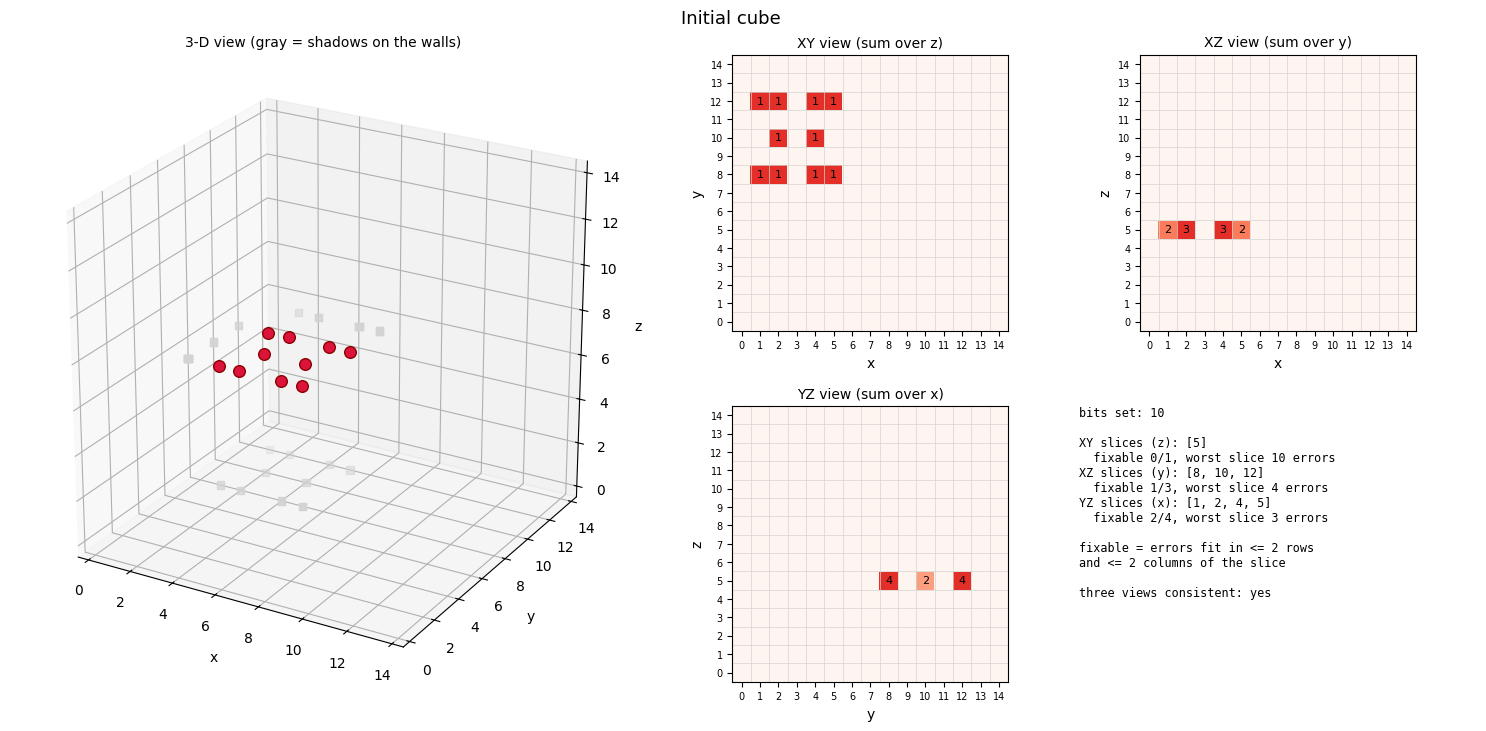

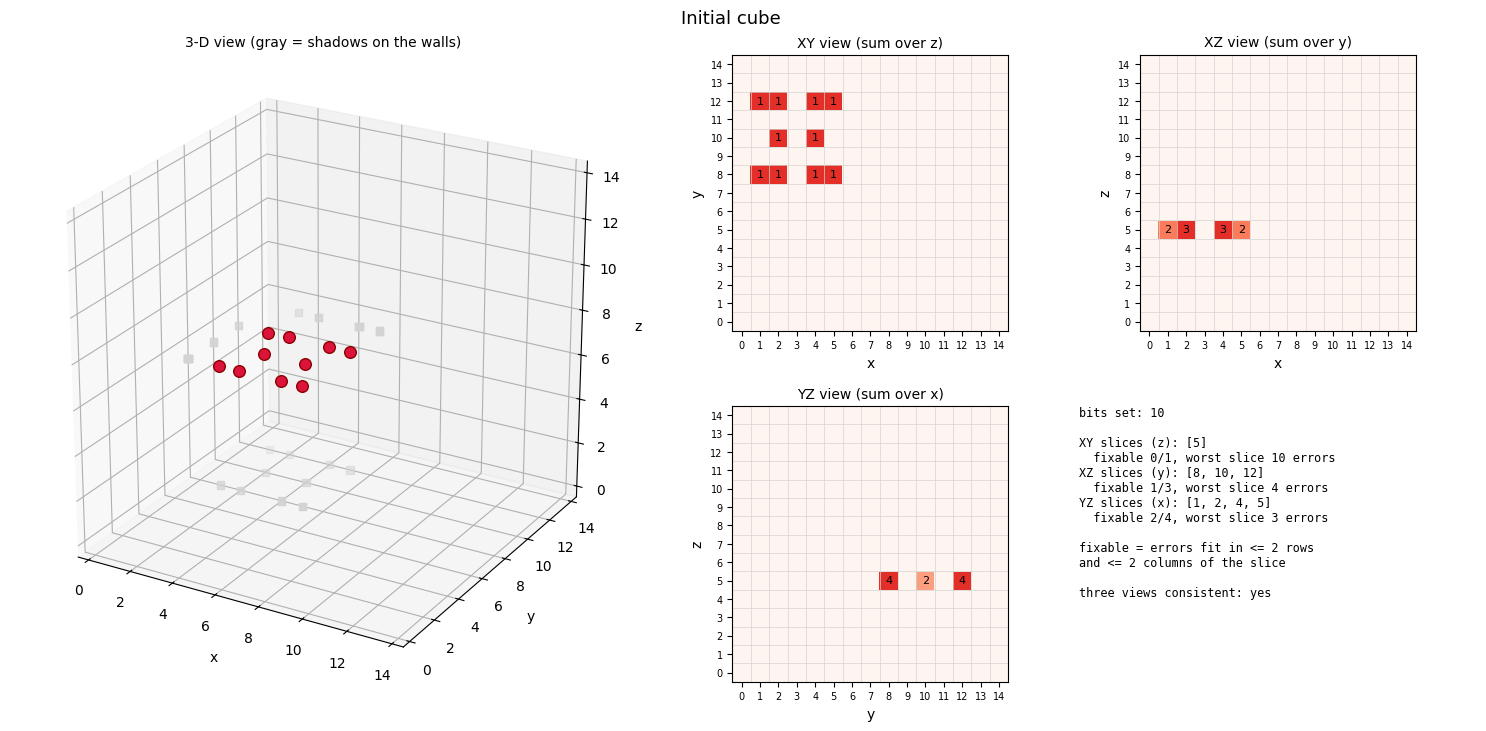

In [ ]:
#Displaying the error cube

test_cube = np.zeros((N, N, N), dtype=np.uint8)

# Introduce sparse errors (up to t=2 errors per plane)

test_cube[1, 8, 5] = 1
test_cube[1, 12, 5] = 1
test_cube[2, 8, 5] = 1
test_cube[2, 10, 5] = 1
test_cube[2, 12, 5] = 1
test_cube[4, 8, 5] = 1
test_cube[4, 10, 5] = 1
test_cube[4, 12, 5] = 1
test_cube[5, 8, 5] = 1
test_cube[5, 12, 5] = 1

# Instantiate the store
test_store = Store(test_cube)

display_cube(test_store, title="Initial cube")

In [ ]:
def check_zero_errors(obj):
    if hasattr(obj, 'to_cube'):
        cube = obj.to_cube(XY)
    else:
        cube = np.asarray(obj, dtype=np.uint8)
    return np.sum(cube) == 0


In [ ]:
#3D PIPELINE

def slice_process(slc):
    err = ecc_2d_silent(slc)
    slc_p = xor_array(slc, err)
    synd = dffft_2t(slc_p)

    synd_sum = sum(sum(row) for row in synd)
    if synd_sum == 0:
        return err
    else:
        return [[0] * len(slc) for _ in range(len(slc))]


def write_corrs(store, o, i, err):
    rows = len(err)
    cols = len(err[0])
    n_flips = 0
    for r in range(rows):
        for c in range(cols):
            if err[r][c] == 1:
                store.flip(o, i, r, c)
                n_flips += 1

    return n_flips

def decode_3d_pipeline(store):
    orientations = [XY, XZ, YZ]
    n_flips_total = 0
    for o in orientations:
        for i in range(N):
            slc = store.read(o, i)
            if sum(sum(row) for row in slc) == 0:
                continue

            err = slice_process(slc)

            if (sum(sum(row) for row in err) > 0):
                n_flips = write_corrs(store, o, i, err)
                n_flips_total += n_flips

    return store.consistent(), n_flips_total

def master_3d(store):
    iter = 0
    while(iter < MAX):
        stat, n_flips_total = decode_3d_pipeline(store)
        if(n_flips_total == 0):
            return True
        iter += 1
    return False

In [ ]:
#3D pipeline (Verbose Version)

def slice_process_v(slc):
    err = ecc_2d_silent(slc)
    slc_p = xor_array(slc, err)
    synd = dffft_2t(slc_p)

    synd_sum = sum(sum(row) for row in synd)
    err_net = sum(sum(row) for row in slc_p)
    if err_net == 0:
        return err
    else:
        return [[0] * len(slc) for _ in range(len(slc))]


def write_corrs_v(store, o, i, err):
    rows = len(err)
    cols = len(err[0])
    n_flips = 0
    for r in range(rows):
        for c in range(cols):
            if err[r][c] == 1:
                store.flip(o, i, r, c)
                n_flips += 1

    return n_flips

def decode_3d_pipeline_v(store, iter):
    orientations = [XY, XZ, YZ]
    n_flips_total = 0
    for o in orientations:
        for i in range(N):
            slc = store.read(o, i)
            #print(f"Decoding slice {i}, orientation : {display_orientation(o)}")
            synd_slc = dffft_2t(slc)
            err = slice_process_v(slc)
            n_flips = write_corrs_v(store, o, i, err)
            n_flips_total += n_flips
        display_cube(store, title = f"cube after {display_orientation(o)} pass at iteration : {iter}")

    return store.consistent(), n_flips_total

def master_3d_v(store):
    iter = 0
    while(iter < MAX):
        stat, n_flips_total = decode_3d_pipeline_v(store, iter)
        if(n_flips_total == 0):
            return check_zero_errors(store)
        iter += 1
    return False

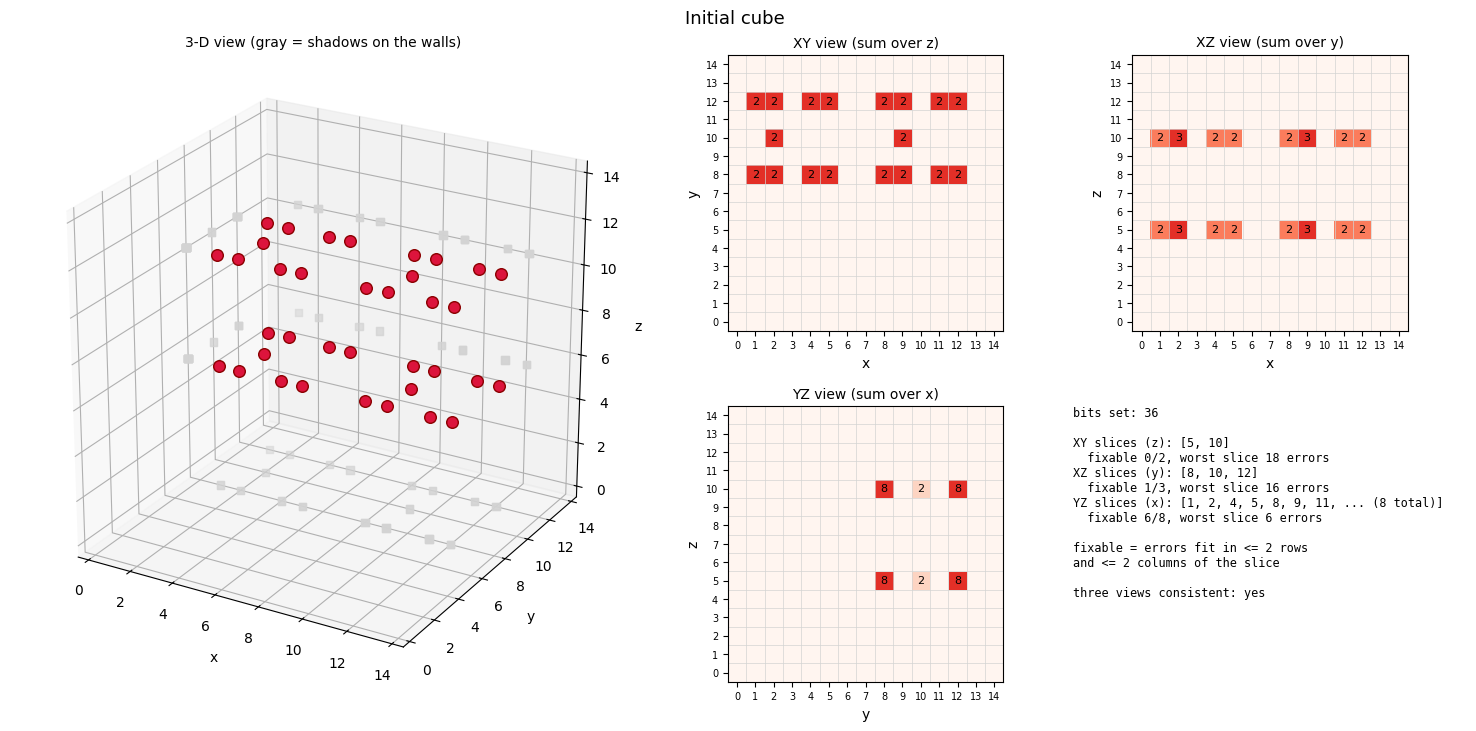

Initial cube has errors: True


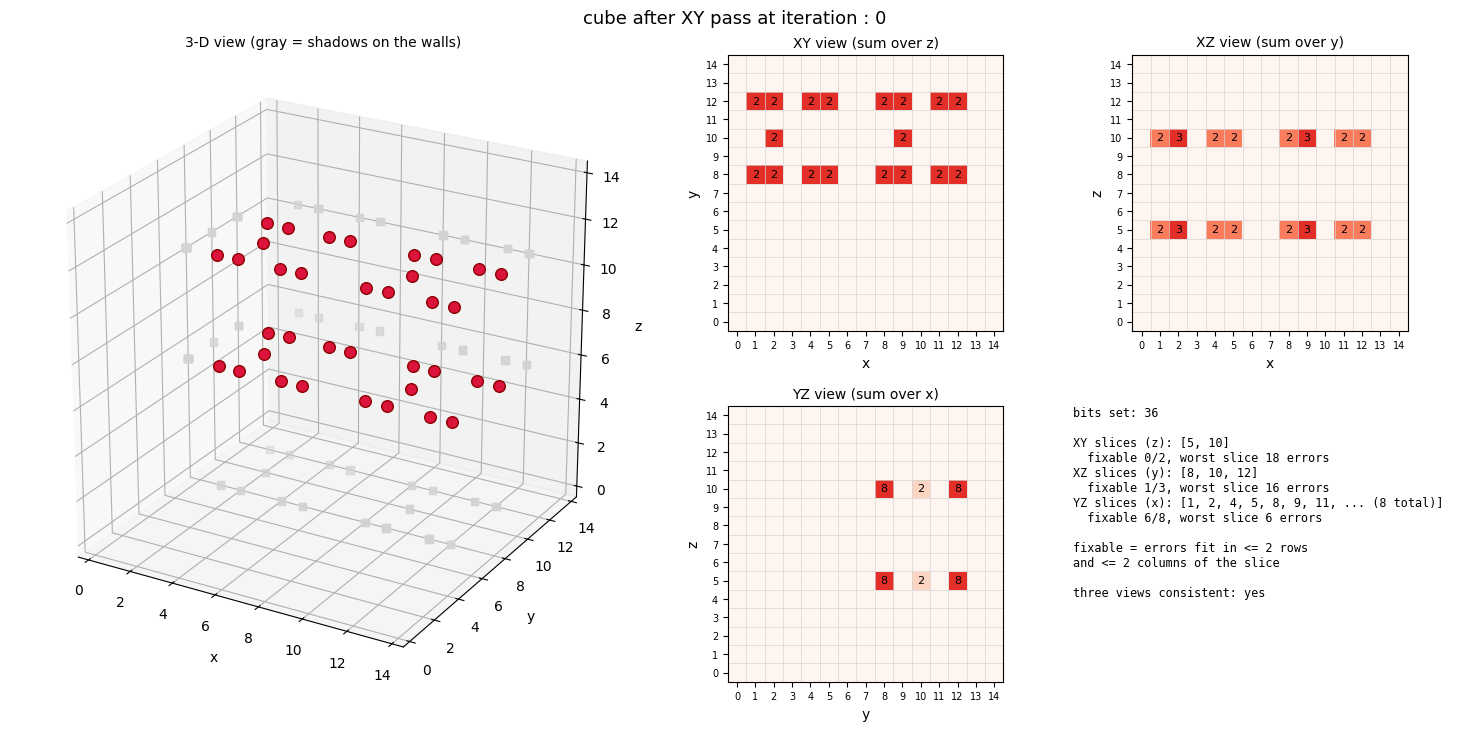

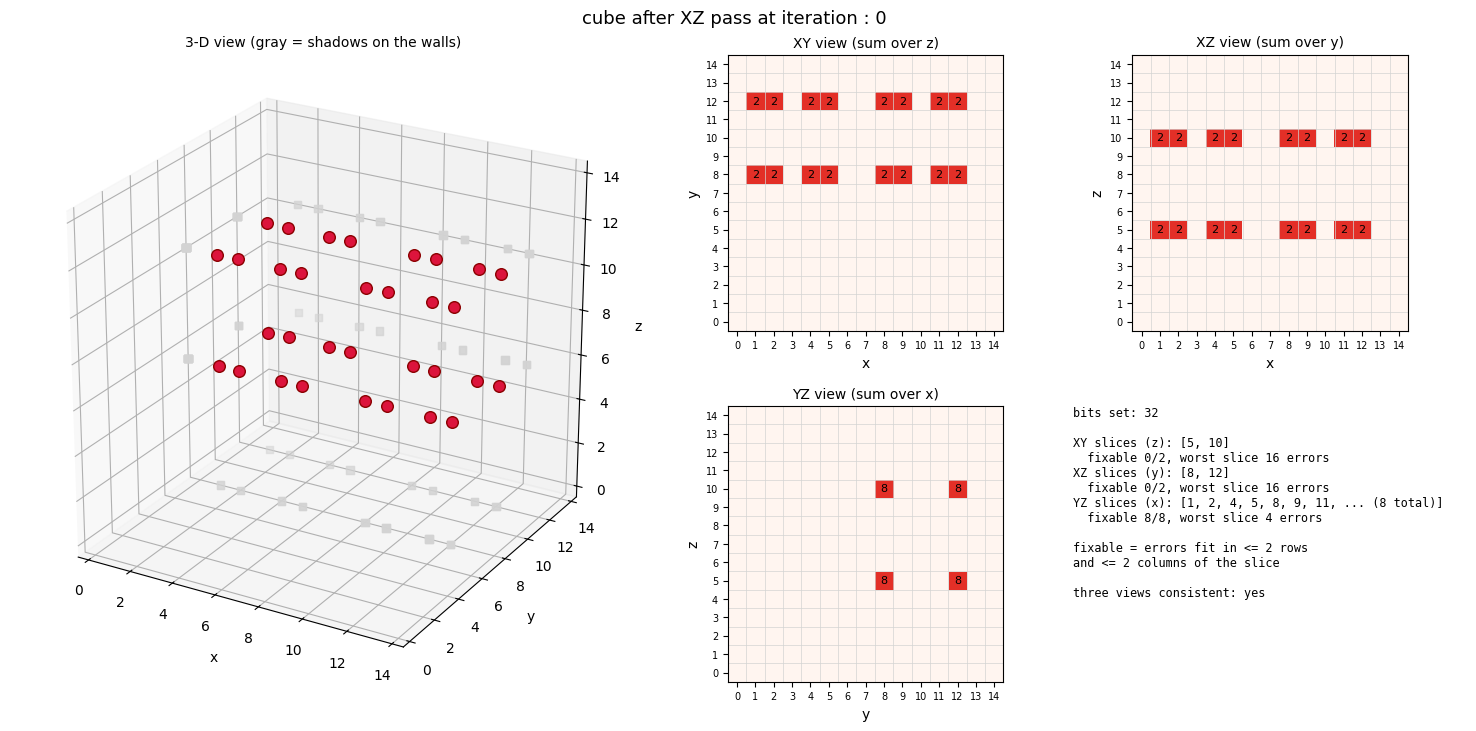

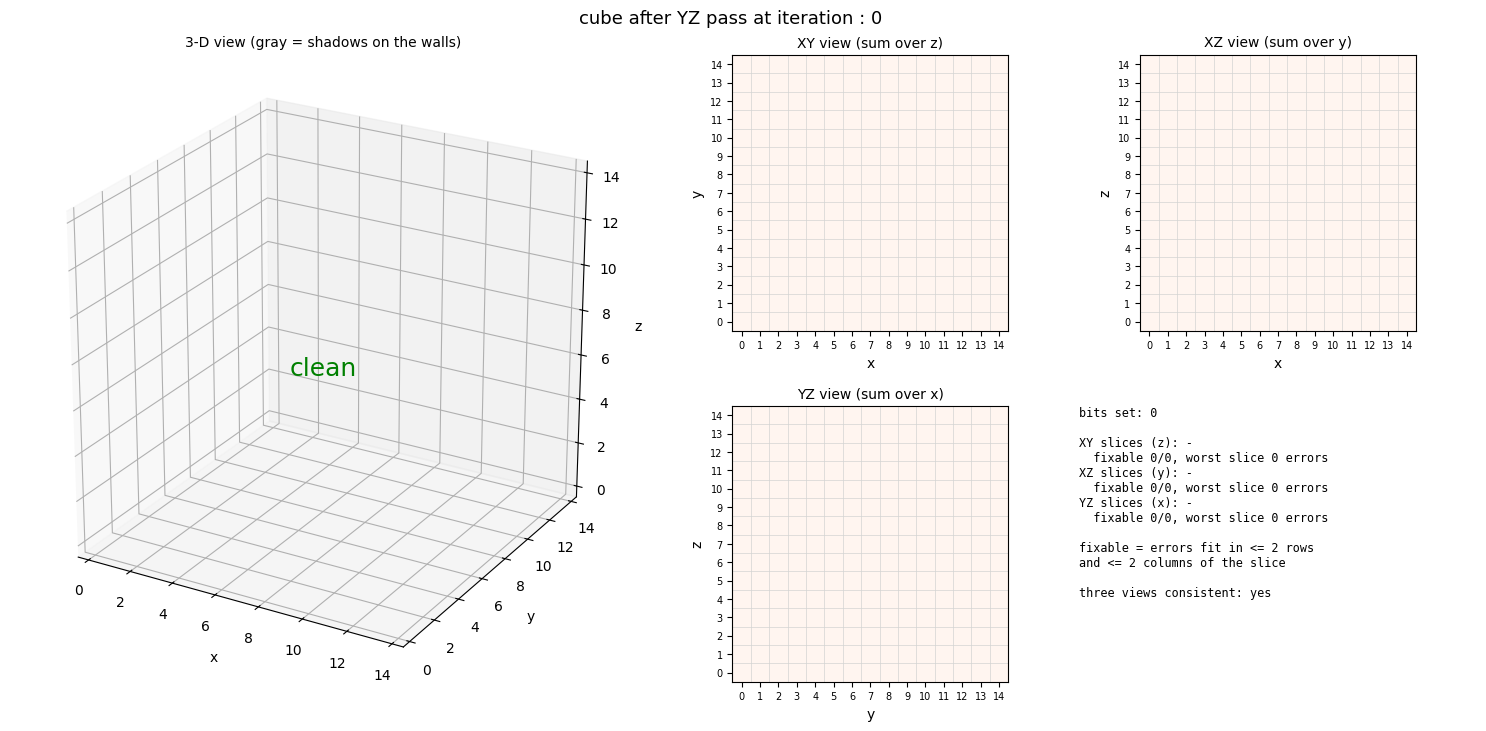

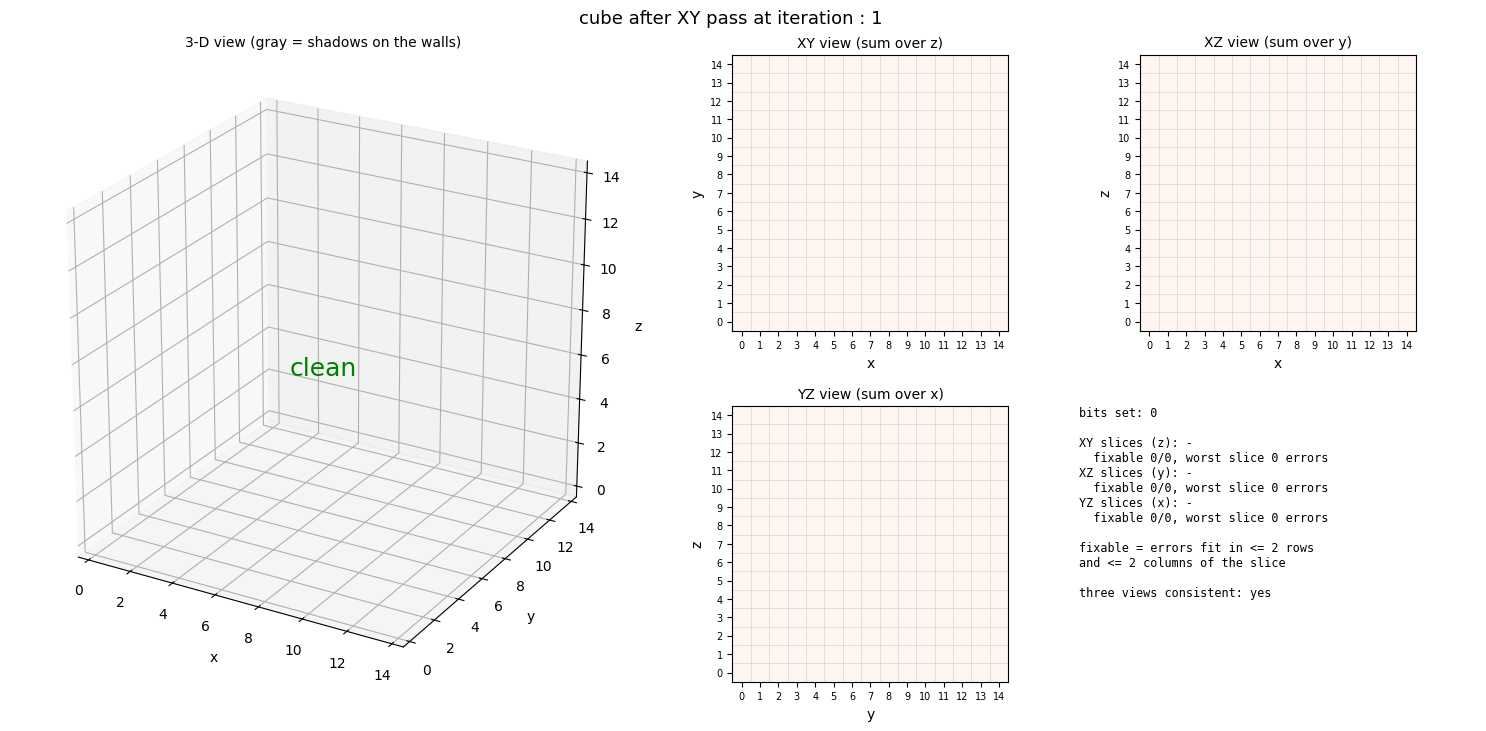

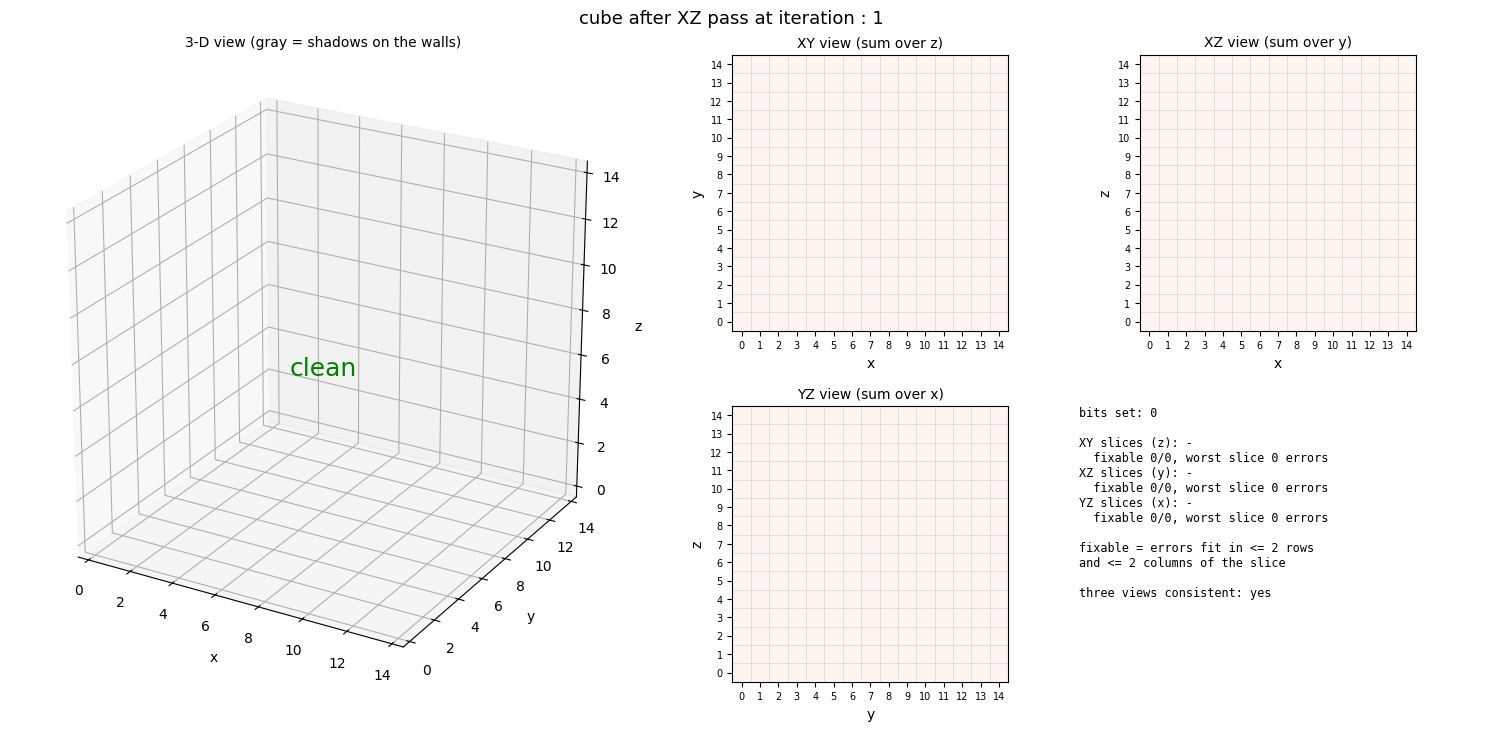

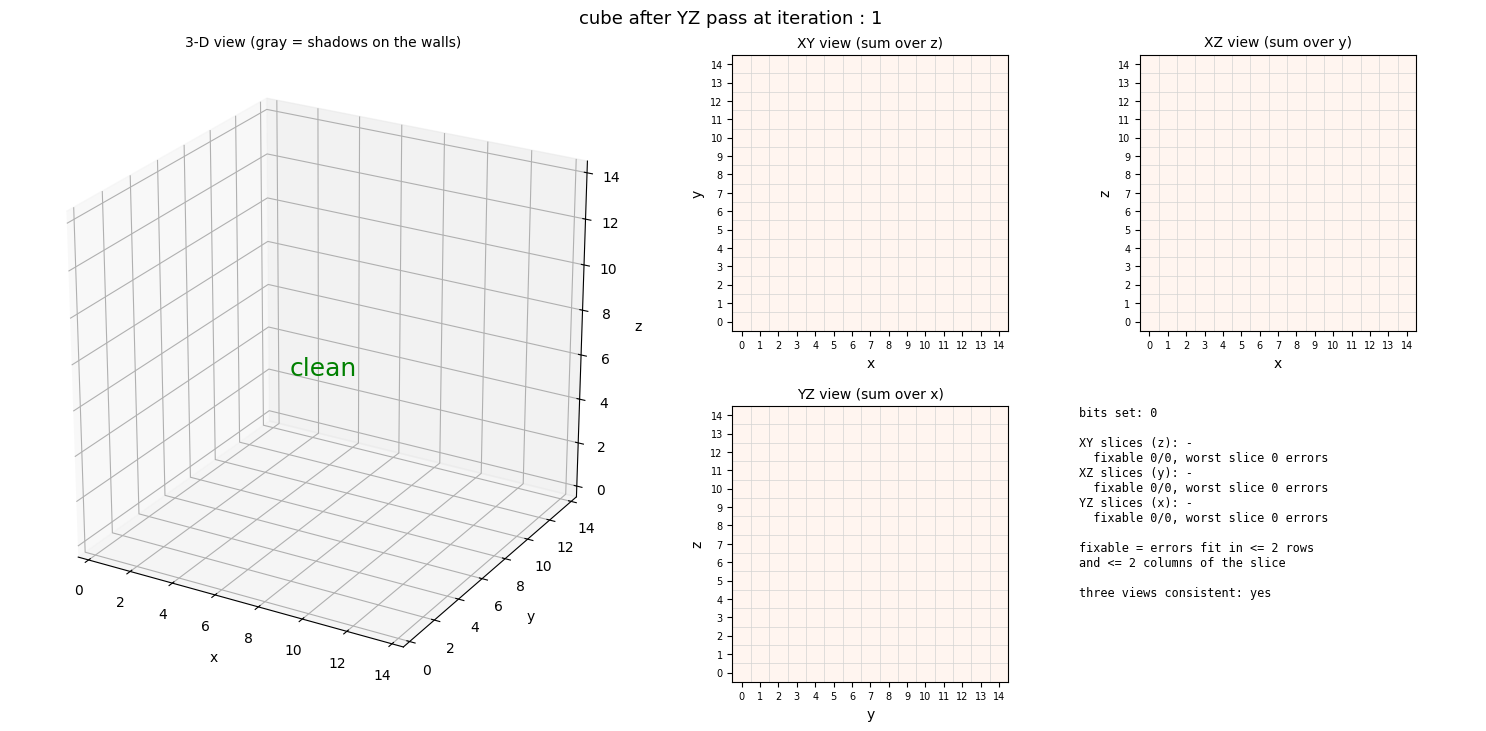

Master 3D Decoder Finished. Success (converged to consistent state): True


In [ ]:
# Test block to verify master_3d function

# Let's create an error cube with known correctable errors
# and verify if master_3d successfully decodes and corrects it.
test_cube = np.zeros((N, N, N), dtype=np.uint8)

# Introduce sparse errors (up to t=2 errors per plane)

test_cube[1, 8, 5] = 1
test_cube[1, 12, 5] = 1
test_cube[2, 8, 5] = 1
test_cube[2, 10, 5] = 1
test_cube[2, 12, 5] = 1
test_cube[4, 8, 5] = 1
test_cube[4, 12, 5] = 1
test_cube[5, 8, 5] = 1
test_cube[5, 12, 5] = 1

test_cube[1, 8, 10] = 1
test_cube[1, 12, 10] = 1
test_cube[2, 8, 10] = 1
test_cube[2, 10, 10] = 1
test_cube[2, 12, 10] = 1
test_cube[4, 8, 10] = 1
test_cube[4, 12, 10] = 1
test_cube[5, 8, 10] = 1
test_cube[5, 12, 10] = 1

test_cube[8, 8, 5] = 1
test_cube[8, 12, 5] = 1
test_cube[9, 8, 5] = 1
test_cube[9, 10, 5] = 1
test_cube[9, 12, 5] = 1
test_cube[11, 8, 5] = 1
test_cube[11, 12, 5] = 1
test_cube[12, 8, 5] = 1
test_cube[12, 12, 5] = 1

test_cube[8, 8, 10] = 1
test_cube[8, 12, 10] = 1
test_cube[9, 8, 10] = 1
test_cube[9, 10, 10] = 1
test_cube[9, 12, 10] = 1
test_cube[11, 8, 10] = 1
test_cube[11, 12, 10] = 1
test_cube[12, 8, 10] = 1
test_cube[12, 12, 10] = 1

# Instantiate the store
test_store = Store(test_cube)

display_cube(test_store, title="Initial cube")

print("Initial cube has errors:", np.sum(test_store.read(XY, 5)) > 0 or np.sum(test_store.read(XY, 10)) > 0)

# Run the 3D master decoder
success = master_3d_v(test_store)

print(f"Master 3D Decoder Finished. Success (converged to consistent state): {success}")

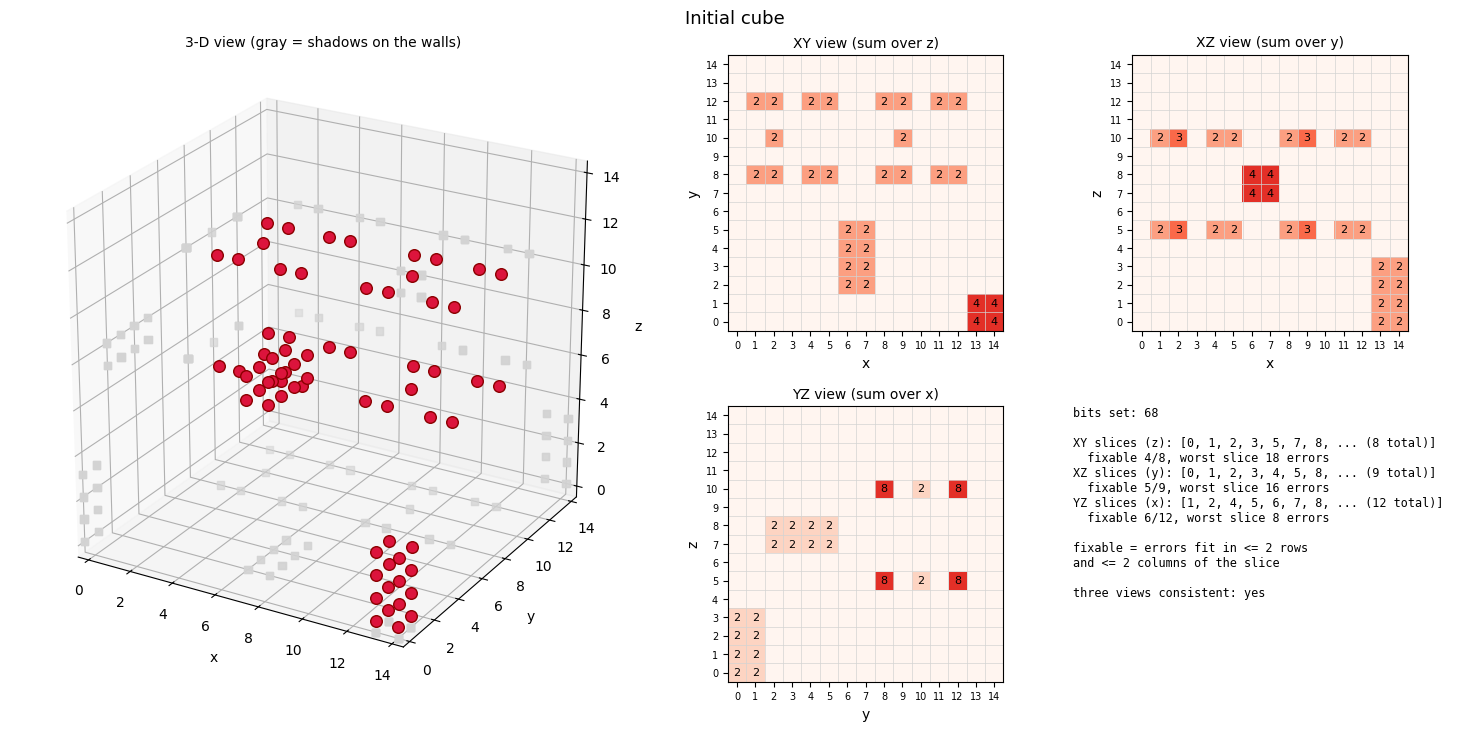

Initial cube has errors: True


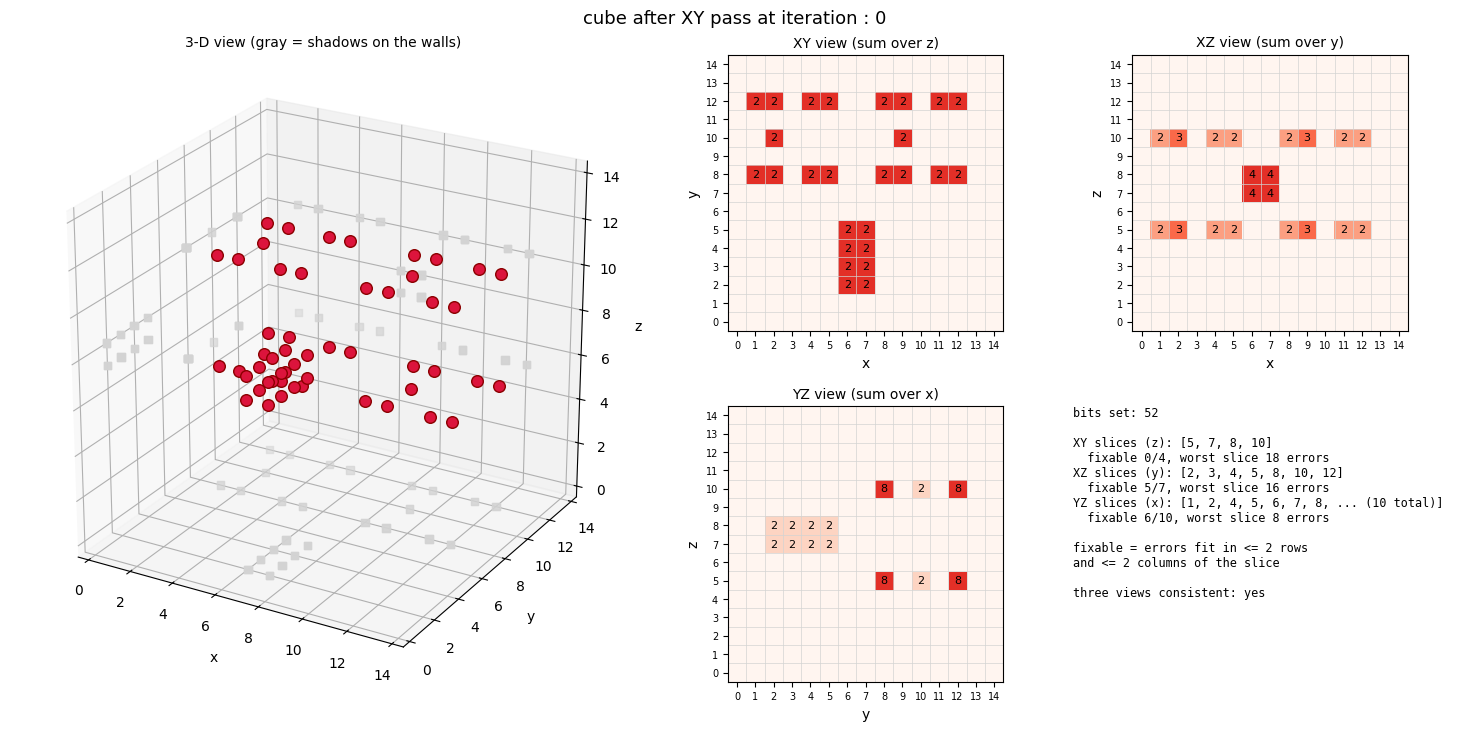

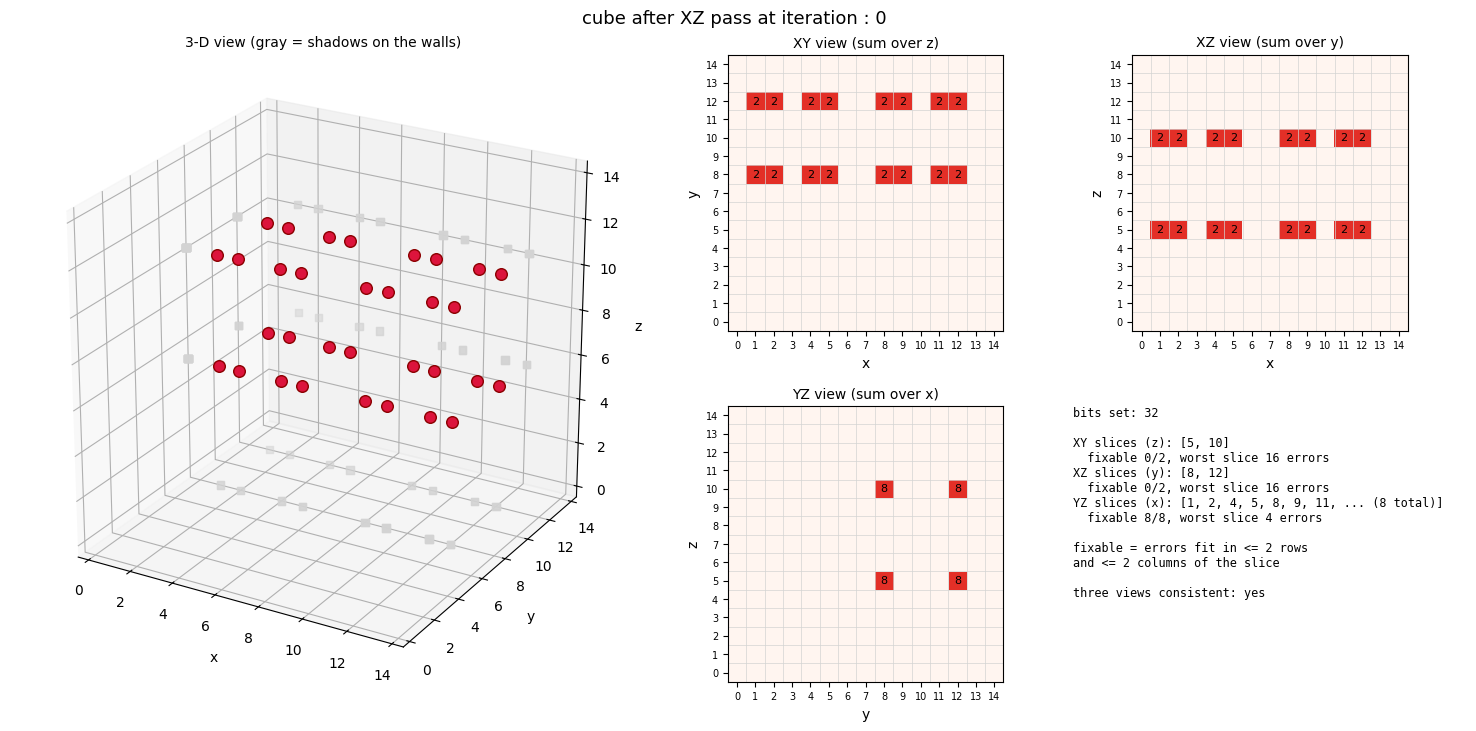

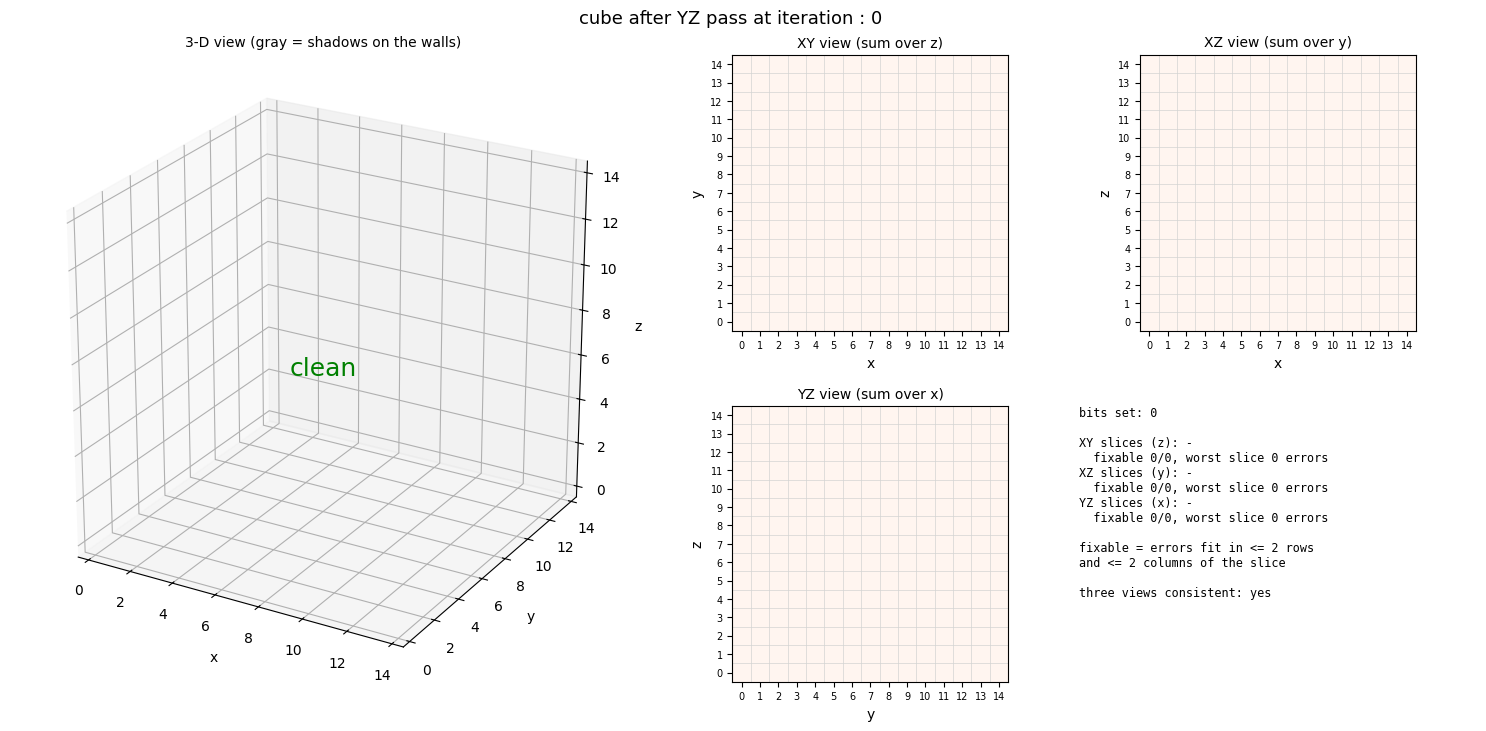

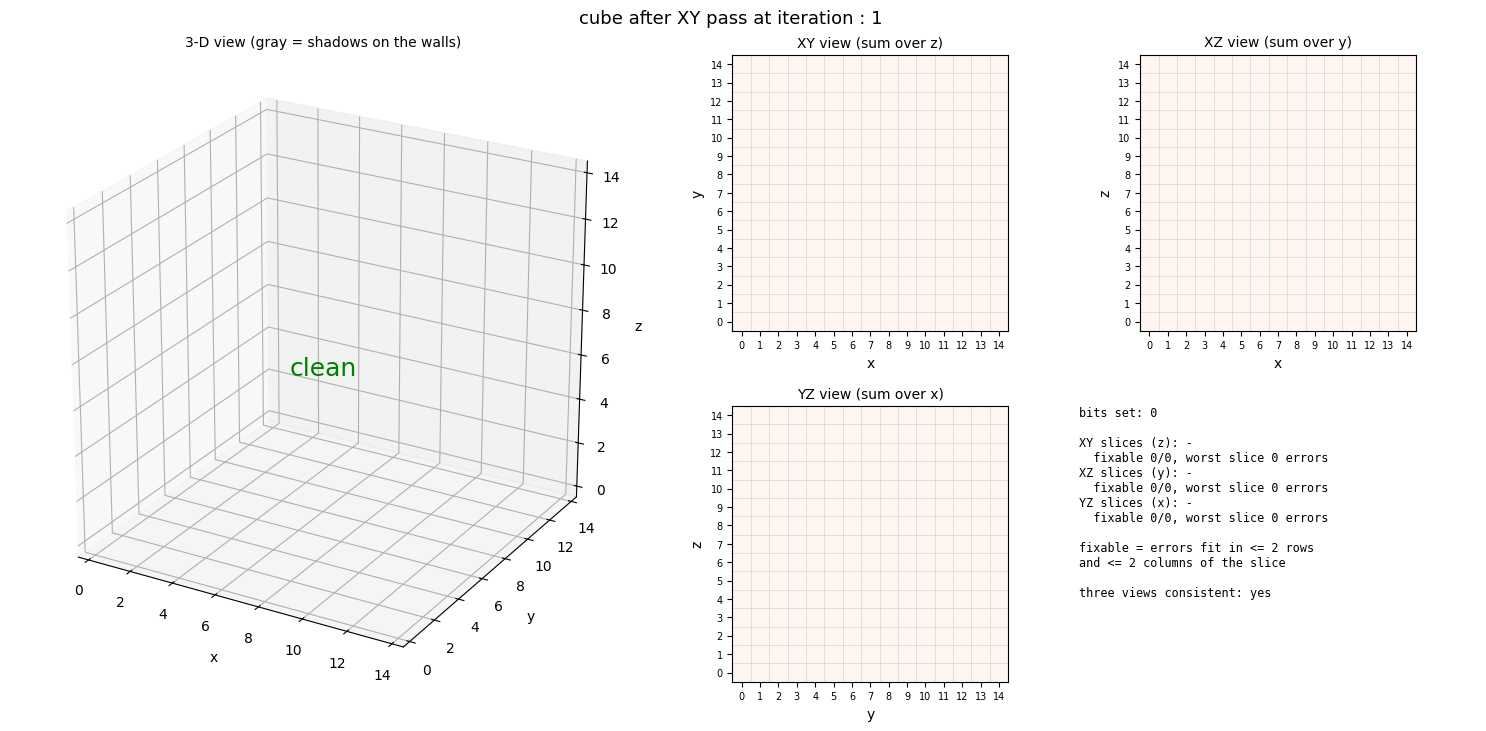

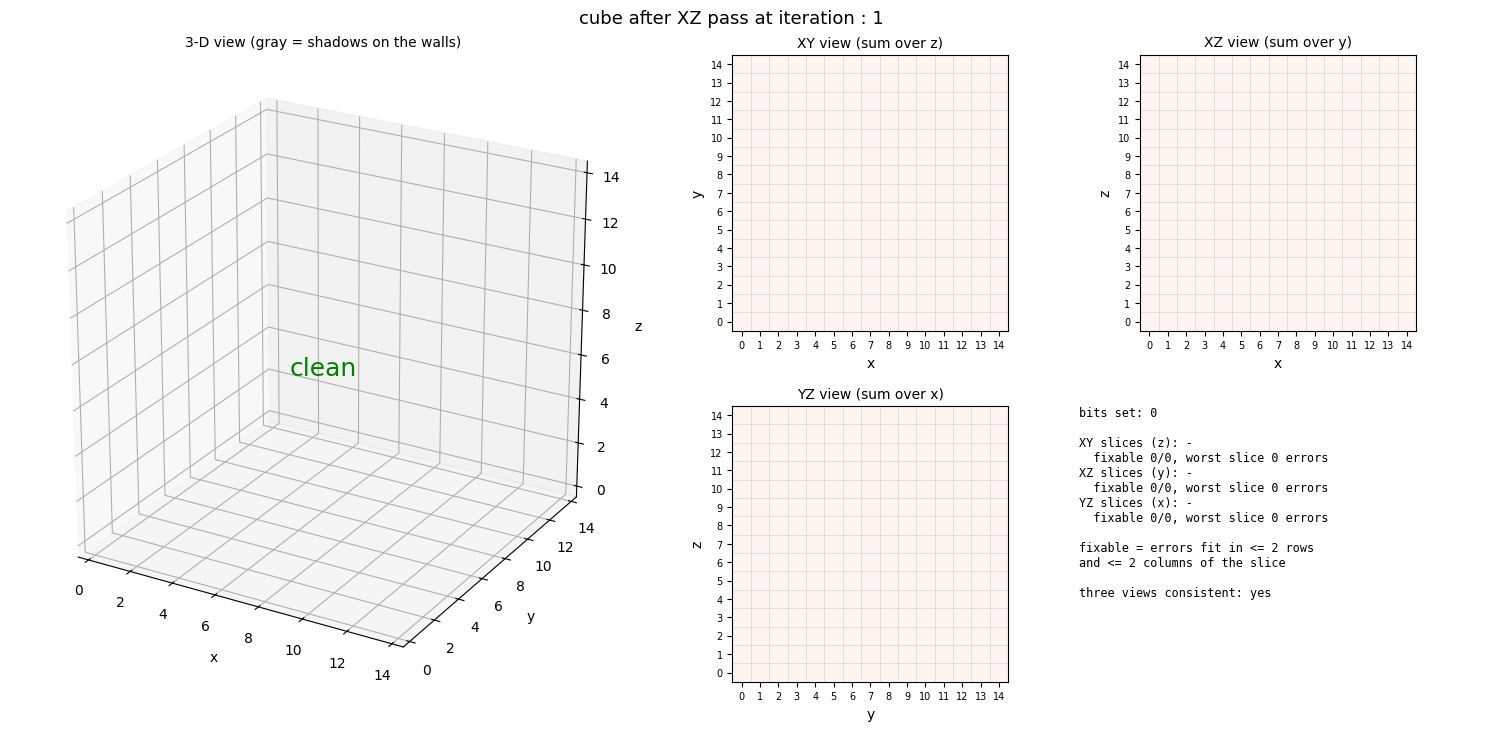

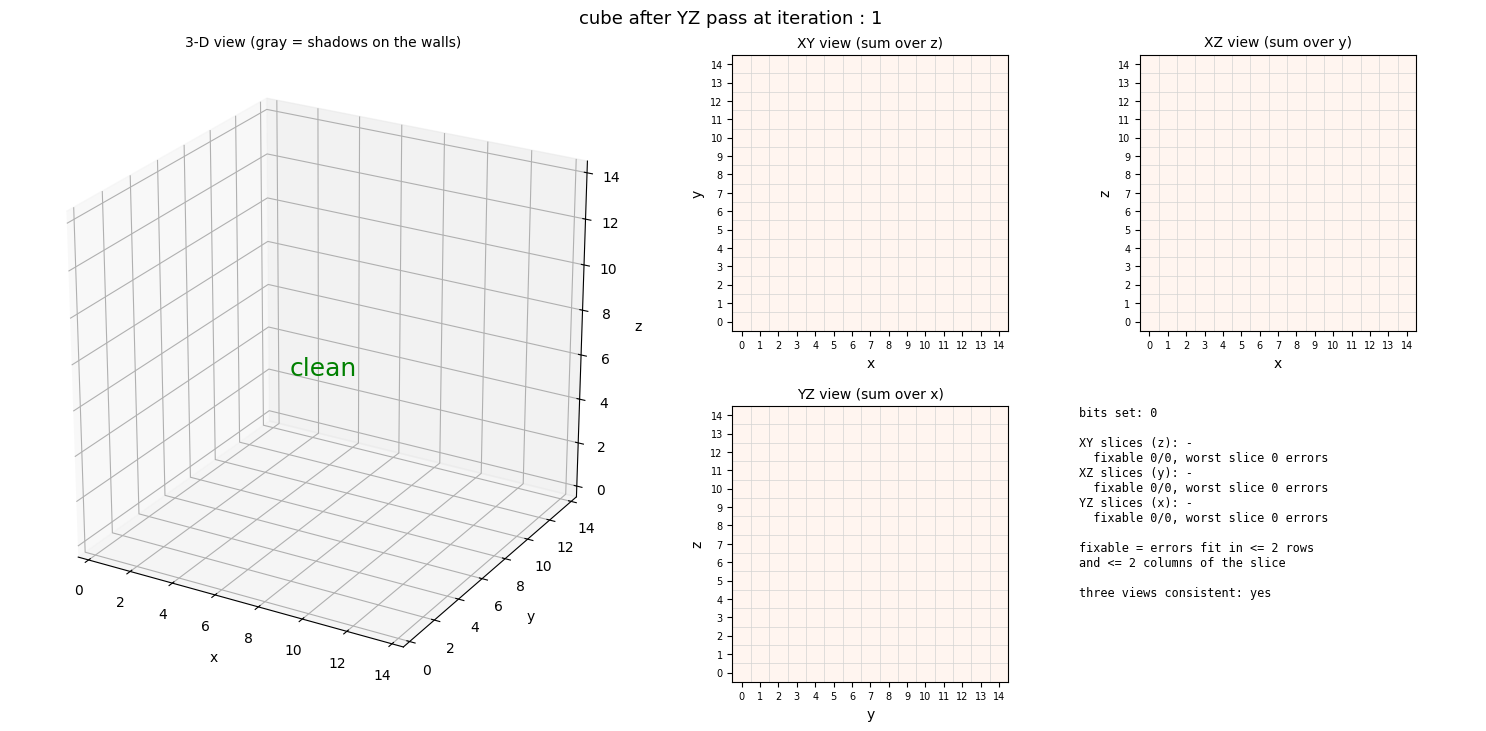

Master 3D Decoder Finished. Success (converged to consistent state): True


In [ ]:
# Test block to verify master_3d function

# Let's create an error cube with known correctable errors
# and verify if master_3d successfully decodes and corrects it.
test_cube = np.zeros((N, N, N), dtype=np.uint8)

# Burst A: 2 x 2 x 4 block. Every XY slice sees a 2x2 square -> fixed in the XY pass
test_cube[13:15, 0:2, 0:4] = 1

# Burst B: 2 x 4 x 2 block. XY slices see 2x4 (too wide), XZ slices see a 2x2 square -> fixed in the XZ pass
test_cube[6:8, 2:6, 7:9] = 1

# Four copies of the pattern from before: XY slices are too spread out to fix,
# the XZ pass fixes only the y=10 slices, which lets the YZ pass fix the rest
test_cube[1, 8, 5] = 1
test_cube[1, 12, 5] = 1
test_cube[2, 8, 5] = 1
test_cube[2, 10, 5] = 1
test_cube[2, 12, 5] = 1
test_cube[4, 8, 5] = 1
test_cube[4, 12, 5] = 1
test_cube[5, 8, 5] = 1
test_cube[5, 12, 5] = 1

test_cube[1, 8, 10] = 1
test_cube[1, 12, 10] = 1
test_cube[2, 8, 10] = 1
test_cube[2, 10, 10] = 1
test_cube[2, 12, 10] = 1
test_cube[4, 8, 10] = 1
test_cube[4, 12, 10] = 1
test_cube[5, 8, 10] = 1
test_cube[5, 12, 10] = 1

test_cube[8, 8, 5] = 1
test_cube[8, 12, 5] = 1
test_cube[9, 8, 5] = 1
test_cube[9, 10, 5] = 1
test_cube[9, 12, 5] = 1
test_cube[11, 8, 5] = 1
test_cube[11, 12, 5] = 1
test_cube[12, 8, 5] = 1
test_cube[12, 12, 5] = 1

test_cube[8, 8, 10] = 1
test_cube[8, 12, 10] = 1
test_cube[9, 8, 10] = 1
test_cube[9, 10, 10] = 1
test_cube[9, 12, 10] = 1
test_cube[11, 8, 10] = 1
test_cube[11, 12, 10] = 1
test_cube[12, 8, 10] = 1
test_cube[12, 12, 10] = 1

# Instantiate the store
test_store = Store(test_cube)

display_cube(test_store, title="Initial cube")

print("Initial cube has errors:", np.sum(test_store.read(XY, 5)) > 0 or np.sum(test_store.read(XY, 10)) > 0)

# Run the 3D master decoder
success = master_3d_v(test_store)

print(f"Master 3D Decoder Finished. Success (converged to consistent state): {success}")